# 02. Resultados

Este notebook no entrena nada. Solo lee lo que generó el pipeline de DVC (`dvc repro`) en `reports/`, para que los resultados siempre correspondan a la última versión de los datos y del código. La justificación de cada algoritmo está en `docs/modelos.md`.

In [1]:
import json
import pandas as pd
from pathlib import Path
from IPython.display import Image, display

REPORTES = Path("..") / "reports"
def leer(nombre):
    return json.loads((REPORTES / "metrics" / nombre).read_text(encoding="utf-8"))

print(json.dumps(leer("limpieza.json"), indent=2, ensure_ascii=False))

{
  "filas_originales": 649,
  "duplicados_quitados": 0,
  "fuera_de_rango": {
    "age": 0,
    "Medu": 0,
    "Fedu": 0,
    "traveltime": 0,
    "studytime": 0,
    "failures": 0,
    "famrel": 0,
    "freetime": 0,
    "goout": 0,
    "Dalc": 0,
    "Walc": 0,
    "health": 0,
    "absences": 0,
    "G1": 0,
    "G2": 0,
    "G3": 0
  },
  "faltantes_antes": {},
  "faltantes_despues": 0,
  "g3_cero_quitados": 15,
  "outliers": {
    "absences": {
      "limite_superior": 15.0,
      "valores_recortados": 21,
      "maximo_original": 32.0
    }
  },
  "filas_finales": 634
}


## 1. Regresión logística

¿Qué factores se relacionan con reprobar, sin conocer ninguna calificación?

{'exactitud': 0.7795, 'precision': 0.3226, 'recall': 0.5882, 'f1': 0.4167, 'log_loss_train': 0.411, 'log_loss_test': 0.5263}


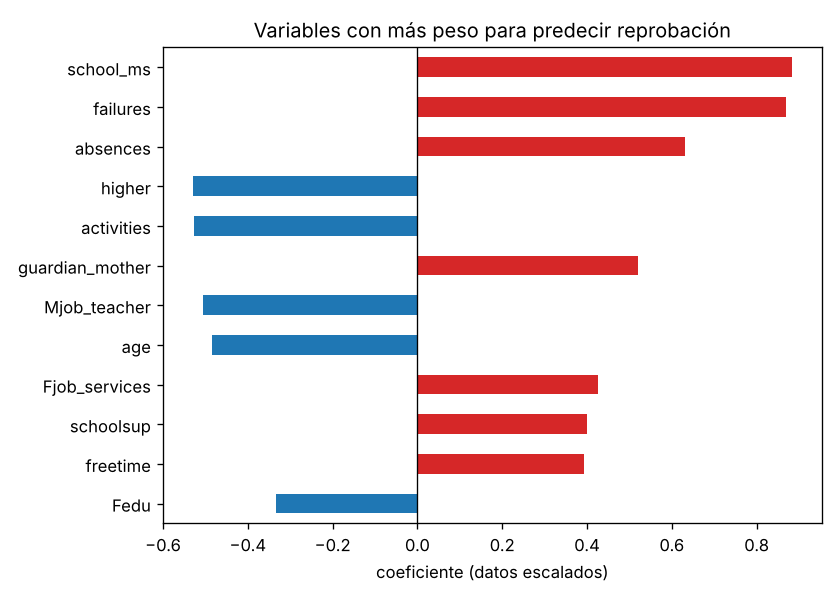

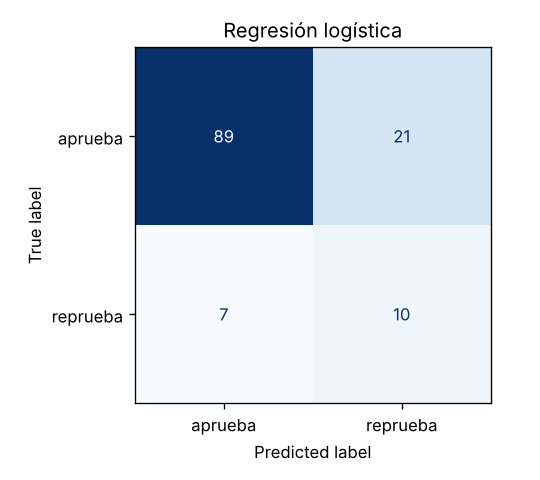

,alumnos,recall,falsas_alarmas
mujeres,77.0,0.5714,0.1714
hombres,50.0,0.6000,0.2250
zona_rural,32.0,0.7500,0.3333
zona_urbana,95.0,0.4444,0.1512


In [2]:
log = leer("logistica.json")
print({k: v for k, v in log.items() if k not in ["equidad", "coeficientes_principales"]})
display(Image(REPORTES / "figures" / "logistica_coeficientes.png"))
display(Image(REPORTES / "figures" / "logistica_matriz_confusion.png"))
pd.DataFrame(log["equidad"]).T

**Interpretación.** _Escribir aquí qué variables pesan más, qué tan bien detecta a los alumnos que reprueban y qué significa la tabla de equidad._

## 2. Árbol de decisión

¿Qué reglas sencillas podría usar una escuela para detectar alumnos en riesgo?

{'exactitud': 0.8346, 'precision': 0.4091, 'recall': 0.5294, 'f1': 0.4615, 'exactitud_train': 0.8619}
{'failures': 0.519, 'higher': 0.246, 'school_ms': 0.132, 'reason_home': 0.074, 'famsize_le3': 0.018, 'health': 0.012}
|--- failures <= 0.50
|   |--- higher <= 0.50
|   |   |--- health <= 3.50
|   |   |   |--- class: 1
|   |   |--- health >  3.50
|   |   |   |--- class: 1
|   |--- higher >  0.50
|   |   |--- school_ms <= 0.50
|   |   |   |--- class: 0
|   |   |--- school_ms >  0.50
|   |   |   |--- class: 0
|--- failures >  0.50
|   |--- reason_home <= 0.50
|   |   |--- famsize_le3 <= 0.50
|   |   |   |--- class: 1
|   |   |--- famsize_le3 >  0.50
|   |   |   |--- class: 1
|   |--- reason_home >  0.50
|   |   |--- class: 0



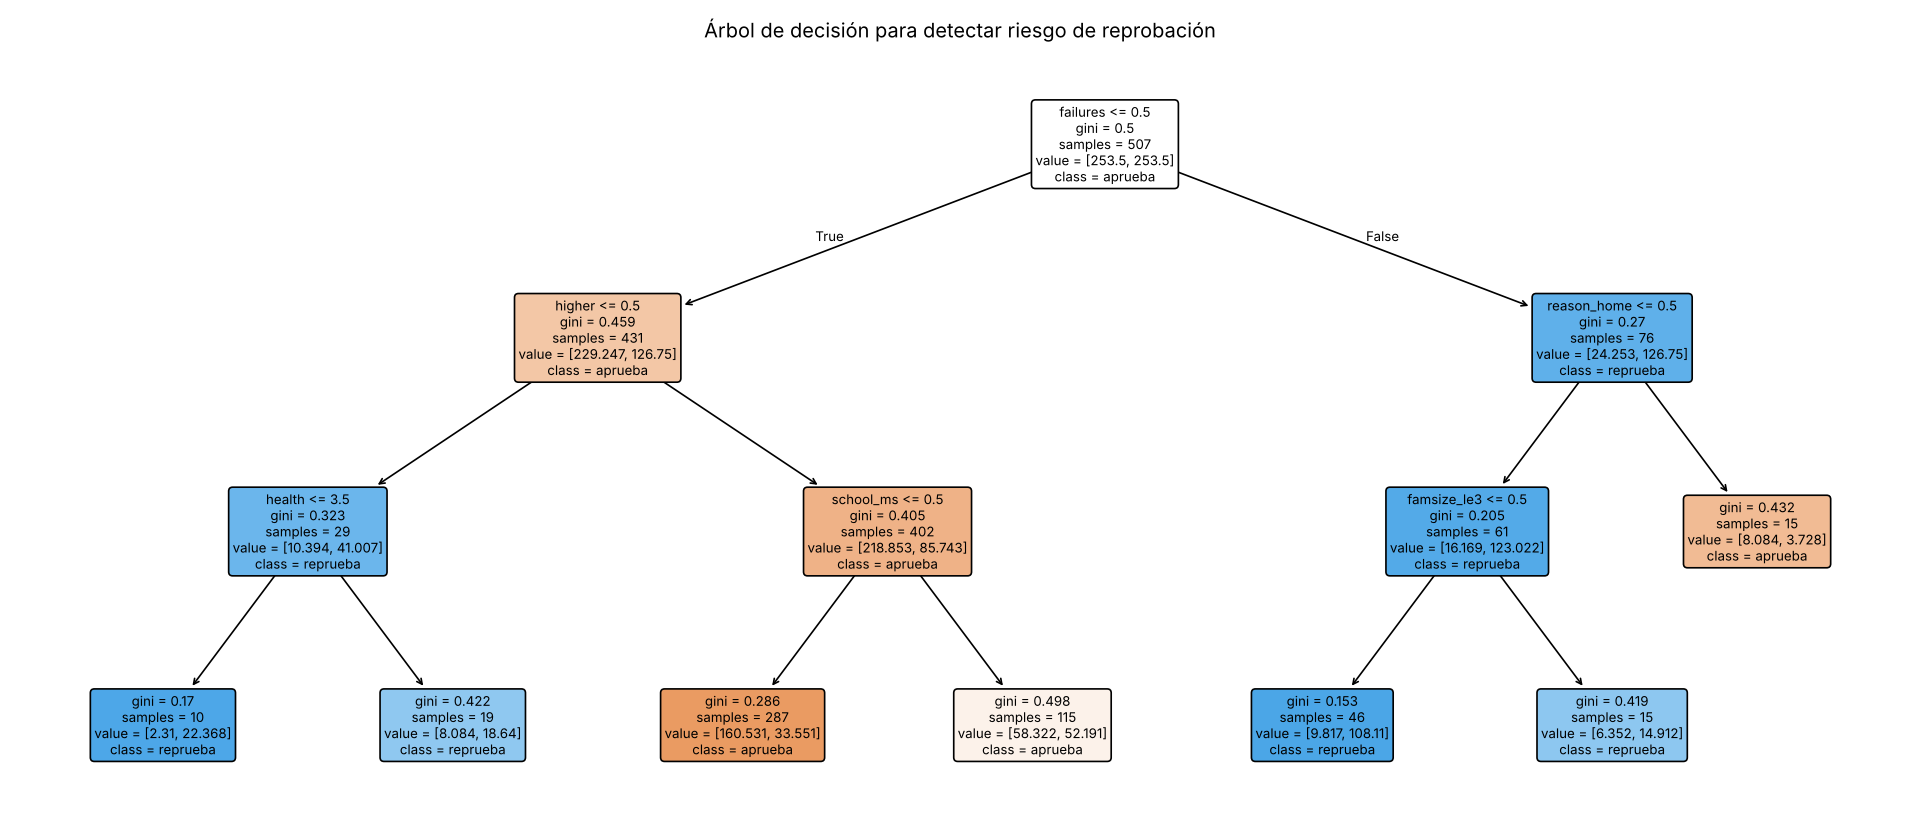

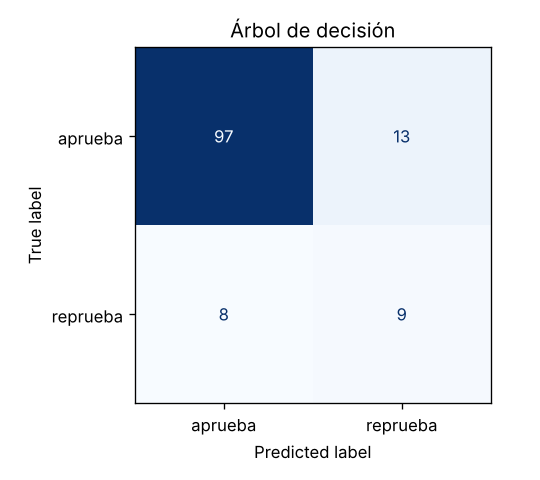

In [3]:
arbol = leer("arbol.json")
print({k: v for k, v in arbol.items() if k not in ["equidad", "importancia_variables"]})
print(arbol["importancia_variables"])
print((REPORTES / "metrics" / "arbol_reglas.txt").read_text())
display(Image(REPORTES / "figures" / "arbol.png"))
display(Image(REPORTES / "figures" / "arbol_matriz_confusion.png"))

In [4]:
# comparacion de los dos modelos de clasificacion
cols = ["exactitud", "precision", "recall", "f1"]
pd.DataFrame({"regresión logística": {c: log[c] for c in cols}, "árbol de decisión": {c: arbol[c] for c in cols}}).T

,exactitud,precision,recall,f1
regresión logística,0.7795,0.3226,0.5882,0.4167
árbol de decisión,0.8346,0.4091,0.5294,0.4615


**Interpretación.** _Escribir aquí las reglas del árbol en palabras y cuál de los dos modelos detecta mejor a los alumnos que reprueban._

## 3. K-means (no supervisado)

¿Qué perfiles de estudiantes hay según sus hábitos y en cuál se reprueba más?

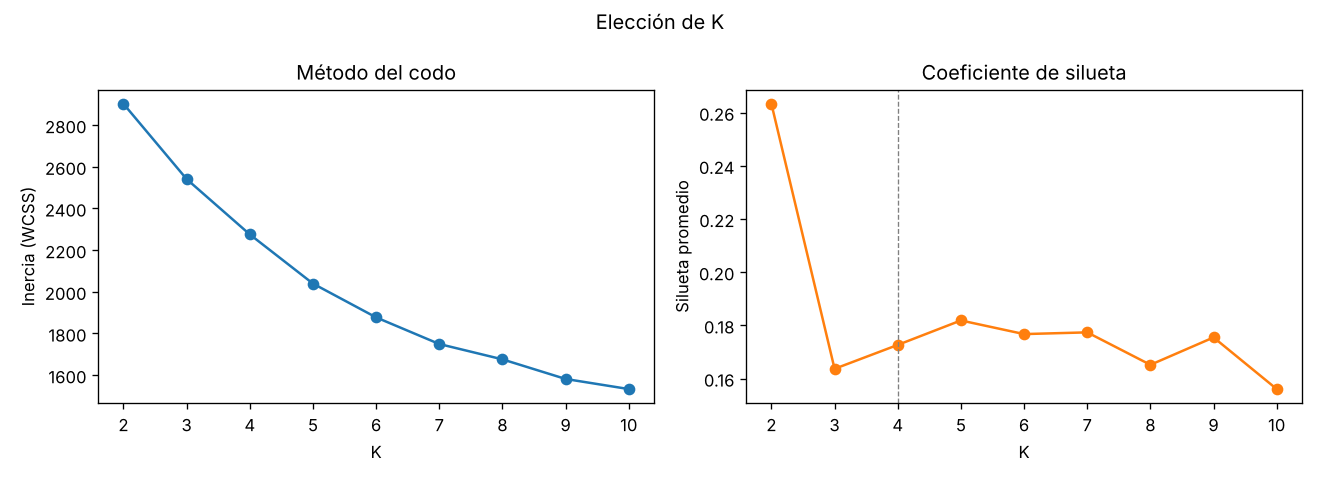

,studytime,freetime,goout,Dalc,Walc,absences,alumnos,porcentaje_reprobados
perfil,,,,,,,,
0,1.74,3.77,3.64,1.14,1.85,2.35,221,13.6
1,3.27,2.96,2.73,1.17,1.62,2.53,113,5.3
2,1.58,2.30,2.28,1.15,1.91,4.22,172,12.2
3,1.61,3.49,4.04,2.85,4.07,5.84,128,21.9


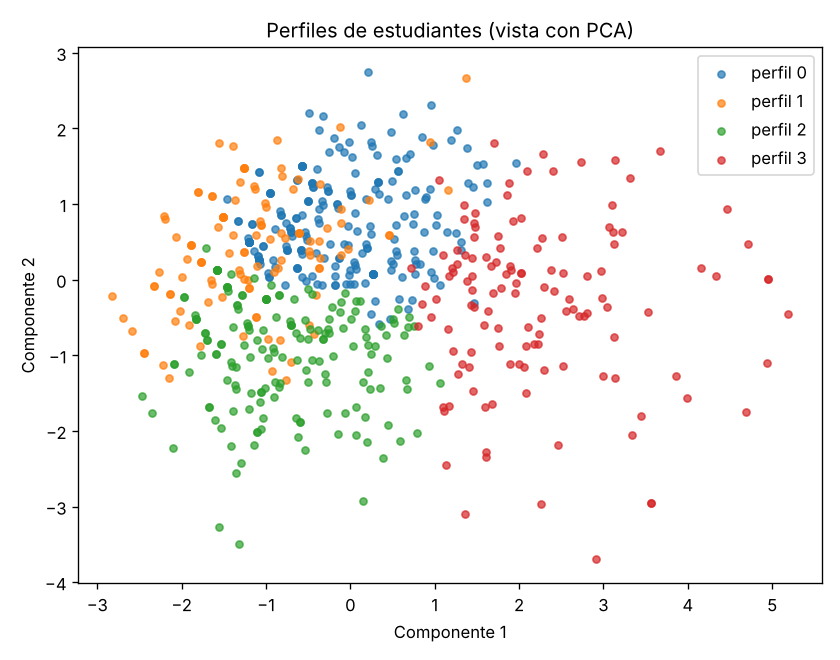

In [5]:
display(Image(REPORTES / "figures" / "kmeans_elegir_k.png"))
display(pd.read_csv(REPORTES / "metrics" / "kmeans_perfiles.csv", index_col="perfil"))
display(Image(REPORTES / "figures" / "kmeans_perfiles_pca.png"))

**Interpretación.** _Escribir aquí por qué se eligió ese K, qué nombre le darían a cada perfil y en cuál se reprueba más._

## 4. Regresión lineal

¿Qué tanto se puede predecir la calificación final y cuánto ayuda conocer la del primer periodo?

,r2,mae,rmse
sin_calificaciones,0.3187,1.8805,2.4329
con_primer_periodo,0.7461,1.0757,1.4852


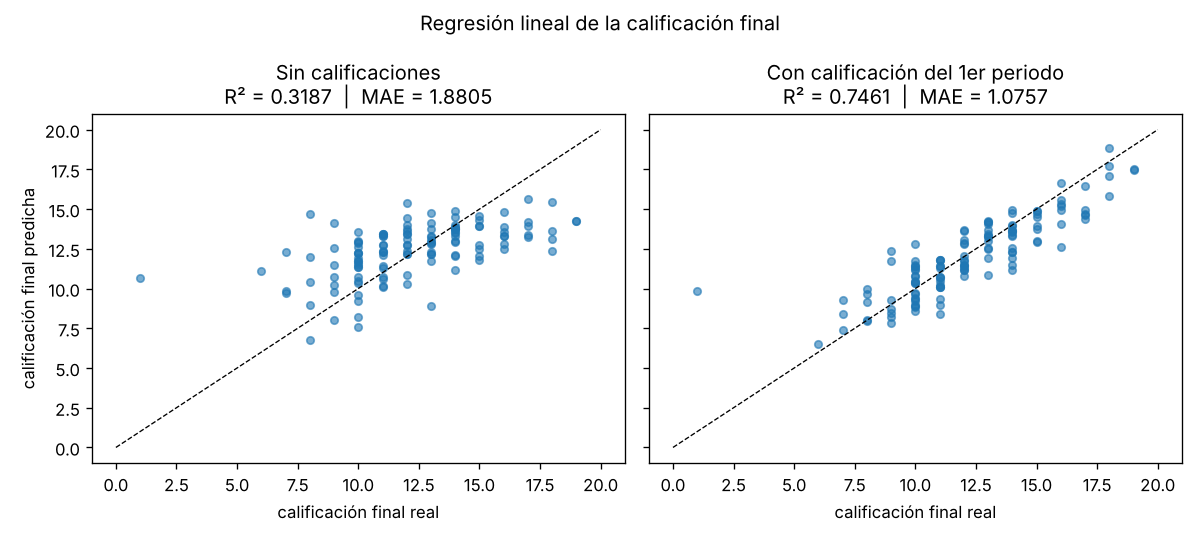

In [6]:
display(pd.DataFrame(leer("lineal.json")).T)
display(Image(REPORTES / "figures" / "lineal_real_vs_predicho.png"))

**Interpretación.** _Escribir aquí la comparación entre los dos modelos y qué quiere decir para una escuela._

## Conclusiones

_Escribir aquí las conclusiones generales. Algunas ideas para guiarlas son qué se pudo responder bien y qué no, qué tienen en común los resultados de los cuatro algoritmos, qué limitaciones tienen los datos y cómo se relaciona todo con el análisis ético de `docs/etica.md`._